# Predicting Heart Disease

## Presented by Muhammad Ahtisham

### Data 201 - Professor Alraee - 10/15/2026



In [51]:
# Importing Google Drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
# Importing Libraries

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
import numpy as np

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

heart = pd.read_csv("/content/drive/MyDrive/Data 201/Datasets/heart.csv") # dataset

## 1. Introduction

In this section, I will explore the dataset and understand what the dataset is before trying to predict whether a case has a heart disease or not.

#### Brief Objective:

In this dataset, my goal is to predict whether a case has a heart disease or not using one of the four classification models: logistic regression, linear discriminant analysis (LDA), quadratic discriminant analysis (QDA), or K-Nearest Neighbors (KNN). Accuracy is not the sole determinant of which model does best; multiple evaluation models, including but not limited to AUC and ROC curves, will be used to determine the best model.  

In [53]:
# Looking at the overall dataset
heart

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [54]:
heart.shape

# Each row represents a patient, and our response variable is the "target" variable. We have 1025 cases, and 14 variables.


(1025, 14)

### Target Variable & Classes

According to the dataset's documentation (https://archive.ics.uci.edu/dataset/45/heart%2BdiseaseHeart?), the target variable is an integer valued variable that is binary. A 1 means there is precense of a heart disease, and a 0 represents no precense of a heart disease. Therefore, we have two classes: Class 1 - Heart Disease, Class 0 - No Heart Disease.


&nbsp;

---
&nbsp;

#### The predictors I believe could be useful for classification:

&nbsp;

*   Age - Subject's age in years **[Quantitative]**
* Sex - Subject's gender **[Qualitative]**
*   cp - cp: chest pain type
        -- Value 1: typical angina
        -- Value 2: atypical angina
        -- Value 3: non-anginal pain
        -- Value 4: asymptomatic **[Qualitative]**
*   chol - Serum cholesterol in mg/dl **[Quantitative]**
* thalach - Maximum heart rate achieved  **[Quantitative]**
* ca - number of major vessels (0-3) **[Qualitative]**

&nbsp;

*Note: The predictors are chosen based on my knowledge of the dataset and what I think would logically be useful to predict heart disease. However, selecting the predictors depends on your domain knowledge, and I don't have strong medical knowledge. Regardless, statistical analysis of these variables will be shown in section 2 to justify why they're possibly useful for predicting heart disease.*

### Distribution of the Target variable

In [55]:
heart['target'].value_counts()

# 526 have had a heart disease. 499 did not. Reasonably balanced

,count
target,
1,526
0,499


In [56]:
heart[['age', 'chol', 'thalach']].describe()

# Although not entirely off, the cholesterol variable does have a higher scale than age and thalach. We may need to watch out for this.

,age,chol,thalach
count,1025.000000,1025.00000,1025.000000
mean,54.434146,246.00000,149.114146
std,9.072290,51.59251,23.005724
min,29.000000,126.00000,71.000000
25%,48.000000,211.00000,132.000000
50%,56.000000,240.00000,152.000000
75%,61.000000,275.00000,166.000000
max,77.000000,564.00000,202.000000


### False Positives & False Negatives

In the context of this data, a false positive would be incorrectly identifying a patient as having a heart disease when they actually didn't. A false negative would be incorrectly identifying a patient as not having a heart disease when they actually did.

In the context of this data, it is important to minimize the false negatives (misses) because we want to be sure that if a patient has a heart disease, we're able to detect that heart disease. On the other hand, false positives (false alarms) are less of a concern because the patient never had a heart disease to begin with.  

## 2. Exploratory Data Analysis (EDA)

In this section, I justify my choices for the predictors, clean the dataset, coerce any variables, split the dataset, and standardize my variables.

&nbsp;

### Investigating the Predictors

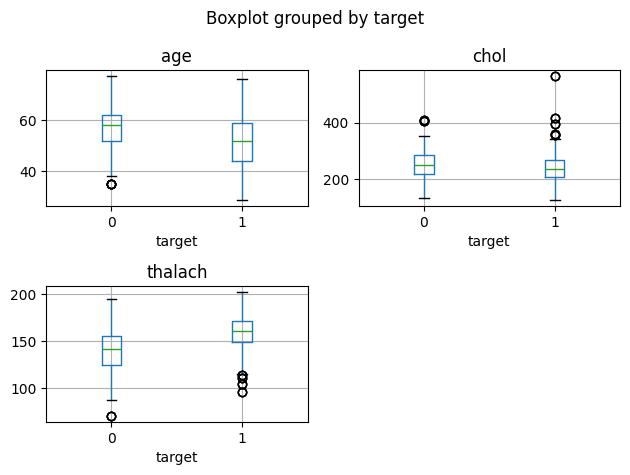

In [57]:
# Graphs of chosen quantitative variables: age, thalach, and chol.
import matplotlib.pyplot as plt

# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 2)

# Plot boxplots
heart.boxplot("age", by="target", ax=axes[0,0])
heart.boxplot("chol", by="target", ax=axes[0,1])
heart.boxplot("thalach", by="target", ax=axes[1,0])


# Remove the unused 4th subplot to keep the layout clean
fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.show()

From the looks of it, age and thalach seem to be significantly varying with heart disease vs. no heart disease. Chol doesn't seem to have the same degree of variation, but there are significantly more outliers for those who had a heart disease (1) than those who didn't (0). I'll create a histogram/distribution graph of the chol variable to further examine it.

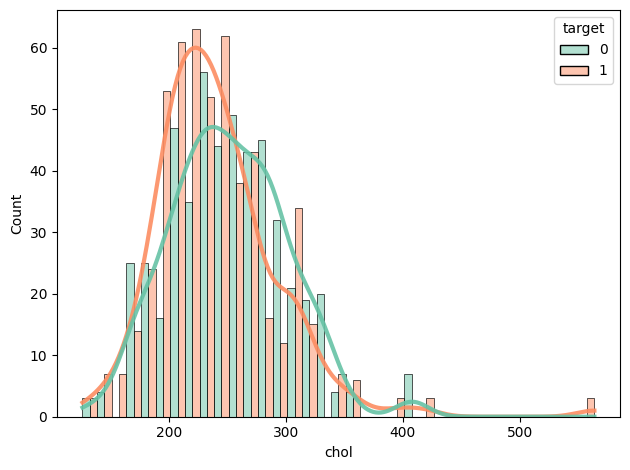

In [58]:

# Distribution plot for chol grouped by target with bold KDE lines
sns.histplot(data=heart, x="chol", hue="target", kde=True, multiple="dodge", palette="Set2", line_kws={'linewidth': 3, 'alpha': 0.9})

plt.tight_layout()
plt.show()

The serum cholesterol of patients is slightly right skewed overall. We see about the same shape for heart disease vs. no heart disease. However, those who did not have a heart disease have a slightly higher mean cholesterol than those who had a heart disease, which is interesting.

Still, from my knowledge of what cholesterol is, I believe it's best to keep the chol variable to predict heart disease or no heart disease. According to the International Journal of Environmental Research and Public Health, serum  cholesterol and LDL-C level (a specific type of cholesterol) are associated with increased cardiovascular disease mortality (Jung et al., 2022)

**The next part goes over the qualitative variables.**

In [59]:
heart.groupby('target')['sex'].value_counts()

target  sex
0       1      413
        0       86
1       1      300
        0      226
Name: count, dtype: int64

Interpretation: We see that when the gender variable is grouped by target, most males (1) did not have a heart disease (0); that is, 413 males did not have a heart disease.



*   86 females (0) did not have a heart disease (0).

*   300 males (1) had a heart disease (1).
* 226 females (0) had a heart disease (1).


I will include the sex variable as a predictor because there seems to be differences across my target variable.

Note: I will use this same reasoning for the rest of the quantitative variables, though it won't be stated because a couple of the variables have more than binary values.

In [60]:
heart.groupby('target')['cp'].value_counts()

# Might be useful as numbers do vary based on the target variable.


target  cp
0       0     375
        2      65
        1      33
        3      26
1       2     219
        1     134
        0     122
        3      51
Name: count, dtype: int64

In [61]:
# Note: Even though the documentation considers the "ca" variable to be an integer, it acts as categorical because the variable categorizes the number of major vessels from 0-4


heart.groupby('target')['ca'].value_counts()

# Again, we see some variation as those who have had a heart attack aggregated towards 0 in the ca variable, while those who didn't varied between 0-2. So, I'll keep it.


target  ca
0       0     163
        1     160
        2     113
        3      60
        4       3
1       0     415
        1      66
        2      21
        4      15
        3       9
Name: count, dtype: int64

### Cleaning the Dataset

In [62]:
# Checking for N/A values

heart.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [63]:
# None of the variables have N/A values, but documentation says ca and thal have missing values. Thal is not important for us, but ca is. I'll investigate it.

In [64]:
heart['ca'].value_counts()

,count
ca,
0,578
1,226
2,134
3,69
4,18


According to documentation, the range for the values is 0-3. However, we see a 4th value. This is likely what the documentation considers a missing value. So, I'll remove the value.

In [65]:
heart = heart[heart['ca'] != 4]

heart['ca'].value_counts()

,count
ca,
0,578
1,226
2,134
3,69


None of the categorical variables need encoding before modeling. A few need one-hot-encoding, however.

Next, I'll split the dataset and use k-fold CV on training data.

random_state = 98 for reproducible results

75% training and 25% testing

**We need to split the dataset, then used k-fold cross-validation.**

**Predictors should be standardized as we saw the chol variable had a higher range, as well as one-hot encoded for categorical.**

**The pipeline and cross-validation will be kept as functions so I can use them for each model instead of recreating the workflow for each model. **

In [66]:
# Defining Features & Target

X = heart[["sex", "age", "cp", "ca", "thalach", "chol"]]
y = heart["target"]

In [67]:
# Standardizing & One-Hot-Encoding

num_cols = ["age", "thalach", "chol"]

cat_cols = ["sex", "cp", "ca"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols), # Standardizing my numerical

    ("cat", OneHotEncoder(handle_unknown="ignore"),
     cat_cols) # One-hot encoding my categorical
])

# Pipeline

def pipeline(model):
  return make_pipeline(preprocess, model) # Creating a pipeline that passes the columntransformer

In [68]:
# Splitting the Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=98
)

In [69]:
# Cross Validation on Training Set

kfold5 = KFold(
    n_splits= 5, # folds
    shuffle=True, # Shuffle-K-Folds
    random_state= 98 # Defining my random state.
)

def cv(model):
  scores = cross_val_score(
      pipeline(model), # Passing a pipeline so it can scale and one-hot encode each fold.
      X_train,
      y_train,
      cv=kfold5,
      scoring='roc_auc'
  )
  return scores.mean()

# We don't get any scores yet because we haven't tested it with any model. In the next section, we'll fit the training data using each of the four classifiers.

Important: scoring = 'roc_auc' was chosen because:

1) ROC-AUC metrics are usually more insightful rather than a flat accuracy because the ROC-AUC looks at all possible thresholds and reports the area under the curve.   
2) The guidelines don't tell us which one to use (accuracy, roc-auc, recall, etc).


## 3. Building the 4 Classifiers

In this section, I will build the following classification models:

1. Logistic Regression
2. LDA
3. QDA
4. KNN


### Logistic Regression

In [70]:
cv(LogisticRegression(max_iter = 2000))

np.float64(0.8975473343360203)

The mean AUC-ROC score of the logistic regression model when trained under k-5 cross-validation is 89.8%. This is a pretty good AUC-ROC score, but the real test still remains.

Below, I train the model using the testing dataset. I display the first 10 test predictions & predicted probabilities:

*Note that the default threshold scikit-learn uses for .predict() is 50%*

In [71]:
# Logistic Regression: Fitting on training set, then using test set.

lr_pipeline = pipeline(LogisticRegression(max_iter=2000))
lr_pipeline.fit(X_train, y_train)

test_preds = lr_pipeline.predict(X_test)
test_probs = lr_pipeline.predict_proba(X_test)[:, 1]

print("Test Predictions:", test_preds[:10])

print("\nTest Probabilities:", test_probs[:10])



Test Predictions: [1 1 0 1 1 1 1 0 0 1]

Test Probabilities: [0.6963579  0.83616945 0.14478876 0.98444263 0.88782303 0.66655871
 0.74512259 0.43689598 0.17621677 0.70107351]


### LDA

In [72]:
cv(LinearDiscriminantAnalysis())

np.float64(0.897730272680171)

The mean AUC-ROC score of the LDA model when trained under k-5 cross-validation is also 89.8%. This is a pretty good AUC-ROC score, but the real test still remains.

Again, I train the model using the testing dataset below. I display the first 10 test predictions & predicted probabilities:

In [73]:
lda_pipeline = pipeline(LinearDiscriminantAnalysis())
lda_pipeline.fit(X_train, y_train)

test_preds_lda = lda_pipeline.predict(X_test)
test_probs_lda = lda_pipeline.predict_proba(X_test)[:, 1]

print("Test Predictions:", test_preds_lda[:10])

print("\nTest Probabilities:", test_probs_lda[:10])

Test Predictions: [1 1 0 1 1 1 1 0 0 1]

Test Probabilities: [0.82746232 0.83638146 0.08954744 0.98932767 0.93909757 0.78640225
 0.86380968 0.45017524 0.13929167 0.79549442]


### QDA

In [74]:
cv(QuadraticDiscriminantAnalysis())

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

np.float64(0.7537322062559934)

The mean AUC-ROC score of the QDA model when trained under k-5 cross-validation is 75.4%. This score isn't the best compared to the past 2.

First 10 test predictions & predicted probabilities after training model on testing dataset:

In [75]:
qda_pipeline = pipeline(QuadraticDiscriminantAnalysis())
qda_pipeline.fit(X_train, y_train)

test_preds_qda = qda_pipeline.predict(X_test)
test_probs_qda = qda_pipeline.predict_proba(X_test)[:, 1]

print("Test Predictions:", test_preds_qda[:10])

print("\nTest Probabilities:", test_probs_qda[:10])

Test Predictions: [1 1 0 1 1 1 1 1 0 1]

Test Probabilities: [9.99983397e-01 9.99997574e-01 6.32915516e-04 9.99999950e-01
 9.99759394e-01 9.98365520e-01 9.99998324e-01 9.66557148e-01
 9.53698773e-05 1.00000000e+00]


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


### KNN

In [76]:
knn_grid = {
    'kneighborsclassifier__n_neighbors': [31, 37, 39, 41, 43, 51],
    'kneighborsclassifier__weights': ['uniform', 'distance']
}

# Because GridSearchCV is like the cv(model) function but with a grid, we can't just use cv(KNeighborsClassifier()) because it'll be redundant and give an error.
# Instead, we create another individual pipeline for the classifier, then pass that pipeline for that model through GridSearchCV using 5 folds for the CV method.

knn_pipeline = pipeline(KNeighborsClassifier())


grid_knn = GridSearchCV(
    knn_pipeline,
    knn_grid,
    cv=kfold5,
    scoring='roc_auc'
)

grid_knn.fit(X_train, y_train)

print("KNN best parameters:", grid_knn.best_params_)
print("KNN best CV ROC-AUC:", round(grid_knn.best_score_, 4))



KNN best parameters: {'kneighborsclassifier__n_neighbors': 41, 'kneighborsclassifier__weights': 'distance'}
KNN best CV ROC-AUC: 0.9986


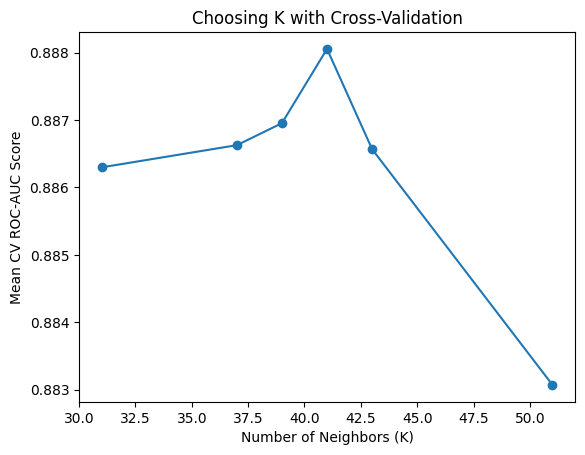

In [77]:
# Graph showing K --> Cross-validation performance:


k_values = [31, 37, 39, 41, 43, 51]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:
    scores_knn = cv(KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(scores_knn.mean())



plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV ROC-AUC Score")
plt.title("Choosing K with Cross-Validation")

plt.show()

K-41 is the best classifier because it gives the best ROC-AUC percentage under the distance weight, as shown by the graph. Even though the values are very close in percentage, 41 gives the highest. I will use this value for the testing dataset. However, regardless of which K that I choose, the mean CV ROC-AUC Score is still pretty high for all of them.

In [78]:
knn_pipeline2 = pipeline(KNeighborsClassifier(n_neighbors=41, weights = "distance"))
knn_pipeline2.fit(X_train, y_train)

test_preds_knn = knn_pipeline2.predict(X_test)
test_probs_knn = knn_pipeline2.predict_proba(X_test)[:, 1]

print("Test Predictions:", test_preds_knn[:10])

print("\nTest Probabilities:", test_probs_knn[:10])

Test Predictions: [0 1 0 1 1 1 1 0 1 1]

Test Probabilities: [0. 1. 0. 1. 1. 1. 1. 0. 1. 1.]


## 4. Evaluating the Models

In this section, we'll evaluate each of the models using metrics such as Accuracy, Precision, Recall, Specificity, F1 Score, and ROC-AUC curves.

Before doing that, if I were to choose a model based on my cross-validation scores, I would choose KNN because it has the highest mean CV ROC-AUC score. However, this is only based on the cross-validation scores, and evaluating using the test dataset can change this tentative decision. Anyways, let's evaluate the models using the test dataset.

### Logistic Regression

In [79]:

#Threshold = 30%
pred = np.where(
    test_probs >= 0.30,
    1,
    0
)

cm = confusion_matrix(
    y_test,
    pred,
    labels=[0, 1]
)

print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

[[ 69  48]
 [  9 126]]
TN: 69
FP: 48
FN: 9
TP: 126


A threshold of **30%**, which is a low threshold, was chosen because we care more about lowering our false negatives (misses) than lowering our false positives (false alarms). As explained earlier, false negatives are more dangerous because it means the model detected a patient as not having a heart disease when they did, as opposed to false positives which mean the model detected them as having a heart disease when they didn't.

Lowering our threshold means classifying more patients as having a heart disease, thereby decreasing our number of false negatives. If we increase our threshold, then that means those who actually had a heart disease have a risk of being identified as not having a heart disease (false negatives).

&nbsp;

We will now evaluate the model using the 30% threshold:

In [80]:
# Scores:
lr_test_accuracy = accuracy_score(y_test, pred)
lr_precision = precision_score(y_test, pred)
lr_recall = recall_score(y_test, pred)
lr_specificity = TN / (TN + FP)
lr_f1 = f1_score(y_test, pred)


lr_test_roc_auc = roc_auc_score(y_test, test_probs) # ROC-AUC gives all possible thresholds, so we don't want to use pred here. Instead, we should use test_probs

print("Accuracy:", round(lr_test_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("Specificity:", round(lr_specificity, 4))
print("F1 Score:", round(lr_f1, 4))

print("\nROC-AUC Score:", round(lr_test_roc_auc, 4))

Accuracy: 0.7738
Precision: 0.7241
Recall: 0.9333
Specificity: 0.5897
F1 Score: 0.8155

ROC-AUC Score: 0.9143


### LDA

In [81]:

#Threshold = 30%
pred_lda = np.where(
    test_probs_lda >= 0.30,
    1,
    0
)

cm_lda = confusion_matrix(
    y_test,
    pred_lda,
    labels=[0, 1]
)

print(cm_lda)

TN_lda, FP_lda, FN_lda, TP_lda = cm_lda.ravel()

print("TN:", TN_lda)
print("FP:", FP_lda)
print("FN:", FN_lda)
print("TP:", TP_lda)

[[ 76  41]
 [  9 126]]
TN: 76
FP: 41
FN: 9
TP: 126


Same threshold was chosen for the same reason explained in logistic regression.

In [82]:
# Scores:
lda_test_accuracy = accuracy_score(y_test, pred_lda)
lda_precision = precision_score(y_test, pred_lda)
lda_recall = recall_score(y_test, pred_lda)
lda_specificity = TN_lda / (TN_lda + FP_lda)
lda_f1 = f1_score(y_test, pred_lda)


lda_test_roc_auc = roc_auc_score(y_test, test_probs_lda)

print("Accuracy:", round(lda_test_accuracy, 4))
print("Precision:", round(lda_precision, 4))
print("Recall:", round(lda_recall, 4))
print("Specificity:", round(lda_specificity, 4))
print("F1 Score:", round(lda_f1, 4))

print("\nROC-AUC Score:", round(lda_test_roc_auc, 4))

Accuracy: 0.8016
Precision: 0.7545
Recall: 0.9333
Specificity: 0.6496
F1 Score: 0.8344

ROC-AUC Score: 0.9109


### QDA

In [83]:

#Threshold = 30%
pred_qda = np.where(
    test_probs_qda >= 0.30,
    1,
    0
)

cm_qda = confusion_matrix(
    y_test,
    pred_qda,
    labels=[0, 1]
)

print(cm_qda)

TN_qda, FP_qda, FN_qda, TP_qda = cm_qda.ravel()

print("TN:", TN_qda)
print("FP:", FP_qda)
print("FN:", FN_qda)
print("TP:", TP_qda)

[[ 67  50]
 [  9 126]]
TN: 67
FP: 50
FN: 9
TP: 126


In [84]:
# Scores:
qda_test_accuracy = accuracy_score(y_test, pred_qda)
qda_precision = precision_score(y_test, pred_qda)
qda_recall = recall_score(y_test, pred_qda)
qda_specificity = TN_qda / (TN_qda + FP_qda)
qda_f1 = f1_score(y_test, pred_qda)


qda_test_roc_auc = roc_auc_score(y_test, test_probs_qda)

print("Accuracy:", round(qda_test_accuracy, 4))
print("Precision:", round(qda_precision, 4))
print("Recall:", round(qda_recall, 4))
print("Specificity:", round(qda_specificity, 4))
print("F1 Score:", round(qda_f1, 4))

print("\nROC-AUC Score:", round(qda_test_roc_auc, 4))

Accuracy: 0.7659
Precision: 0.7159
Recall: 0.9333
Specificity: 0.5726
F1 Score: 0.8103

ROC-AUC Score: 0.8157


### KNN

In [85]:
#Threshold = 30%
pred_knn = np.where(
    test_probs_knn >= 0.30,
    1,
    0
)

cm_knn = confusion_matrix(
    y_test,
    pred_knn,
    labels=[0, 1]
)

print(cm_knn)

TN_knn, FP_knn, FN_knn, TP_knn = cm_knn.ravel()

print("TN:", TN_knn)
print("FP:", FP_knn)
print("FN:", FN_knn)
print("TP:", TP_knn)

[[117   0]
 [  0 135]]
TN: 117
FP: 0
FN: 0
TP: 135


In [86]:
# Scores:
knn_test_accuracy = accuracy_score(y_test, pred_knn)
knn_precision = precision_score(y_test, pred_knn)
knn_recall = recall_score(y_test, pred_knn)
knn_specificity = TN_knn / (TN_knn + FP_knn)
knn_f1 = f1_score(y_test, pred_knn)


knn_test_roc_auc = roc_auc_score(y_test, test_probs_knn)

print("Accuracy:", round(knn_test_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("Specificity:", round(knn_specificity, 4))
print("F1 Score:", round(knn_f1, 4))

print("\nROC-AUC Score:", round(knn_test_roc_auc, 4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Specificity: 1.0
F1 Score: 1.0

ROC-AUC Score: 1.0


## 5. Reflection

The metrics that are particularly important in evaluating the model based on the domain knowledge are Recall and possibly the F1 Score. The ROC-AUC score is also important because one threshold may not cover all posibilities.

We want to avoid as many false negatives as possible, and when the recall is high, we have low false negatives. However, a high recall means more false positives, and we don't want to identify every patient as having a heart disease when they don't. This is why I also chose F1 score because it is the harmonic mean between precision (high precision --> low false positives) and recall.

With that in mind, I will go over what was discovered.



---



**Logistic regression:**


*   Recall: 0.9333

*   F1 Score: 0.8344

* ROC-AUC Score: 0.9143


These are pretty good metrics. Our recall is high, meaning we don't have a lot of misses. The F1 score is also good, meaning our precision is also decent. The ROC-AUC score indicates that the model performs well on all thresholds.
&nbsp;

**LDA:**

* Recall: 0.9333
* F1 Score: 0.8155
* ROC-AUC Score: 0.9109



Explanation: These are also pretty good metrics. The Recall is identical to logistic regression's recall score. The ROC-AUC score is very similar to logistic regression's score but slightly lower. The F1-score is also slightly lower than logistic regression.

&nbsp;

**QDA:**

* Recall: 0.9333
* F1 Score: 0.8103
* ROC-AUC Score: 0.8157

Explanation: These metrics are also similar to LDA and logistic regression, but the ROC-AUC score is lower by about 10%. This means that the area under the curve for this model is ~82%. Still better than a coin flip.

&nbsp;

**KNN:**

* Recall: 1.0
* F1 Score: 1.0
* ROC-AUC Score: 1.0

Explanation: We have a 100% metrics for everything, meaning the model did perfectly well on seen and "unseen" data (testing data). Something is wrong:

This is likely because the dataset that was received was over-cleaned. There were extra, possibly duplicate, rows that were added for education purposes to this dataset. When splitting the data, some of those extra and duplicate rows went in both the training and testing dataset.

So, the KNN model got perfect accuracy because it looked at the distance of the nearest point in the training dataset, chose its classification, but saw that the same point and classification exist in the testing dataset as well because there's a duplicate in both the training & testing!

&nbsp;

**Best Model:**

There are clear two winners: logistic regression & LDA. QDA has a lower ROC-AUC score than logistic and LDA. KNN has inflated metrics (100% for all of them), which I've talked about above.

The choice comes down to logistic and LDA. For this application, I would consider logistic regression as the better model because it is simpler than LDA. Therefore, **logistic regression is the best model** out of the four that we've built and evaluated.

Below, I create an ROC-AUC curve for logistic regression:

## 6. Logistic Regression: ROC and AUC

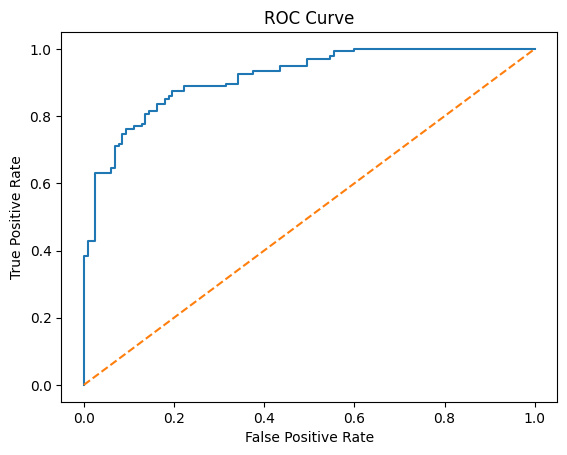

In [87]:
#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probs
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

The ROC-AUC score for logistic regression is 0.9109. This means that the area under the curve is 91% when considering all thresholds. For reference, if it was 50%, it would be as if we're flipping a coin. This is a good score for logistic regression.


## 7. Final Analysis & Conclusions

**1\) Comparing the Four Classifiers**

Our goal with each model is to minimize how much the model falsely classifies someone as having no heart disease when they actually have one. With that, we need to make sure that the model is also decent in detecting when there actually is a heart disease.

Each model does well on classifying someone with a heart disease when they actually had it and ensuring it doesn't classify someone as having no heart disease when they did. Each model, besides KNN, had a score of 93% on the metric that tells us how much we classified patients with a heart disease out of every patient who actually had a heart disease (Recall).


An importance difference is seen when considering all types of "possibilities"  (ROC-AUC curve). QDA had the lowest score when considering all types of possibilities (thresholds), with a score of ~82%, while LDA and logistic regression both had a score of ~91%. KNN had a score of 100%, but we'll talk about that later.

**2\) Best & Simple Model**

The model that I would deploy for this specific application would be logistic regression. QDA had the lowest score when considering all types of thresholds (ROC-AUC score), and it also isn't the simplest model, so that's out the door. KNN has 100% of everything, which is a red flag that I'll explain more in the next step, so that's out the door. LDA and logistic regression are very similar in their metrics, but the simpler one is logistic regression.


Therefore, the model I would deploy for this application would be **logistic regression.**

**3\) A Limitation**

A limitation of my analysis was the over-cleaning done by the providers of the dataset. There were supposed to be 303 instances according to the documentation, but for education purposes, more rows that are possibly duplicates were added. This is likely why KNN has 100% on every metric, including the ROC-AUC scores.

**4\) The Real World**

Before using this model in the real world, I would like to see the distribution of my classes based on my predictors to see their normality and spread. I would also be very cautious of using KNN in the real world considering the supposedly duplicate rows. If I'm given a dataset where they are removed, then I would consider KNN.

## Sources:

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). Heart Disease [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X.

Jung, E., Kong, S. Y., Ro, Y. S., Ryu, H. H., & Shin, S. D. (2022). Serum Cholesterol Levels and Risk of Cardiovascular Death: A Systematic Review and a Dose-Response Meta-Analysis of Prospective Cohort Studies. International journal of environmental research and public health, 19(14), 8272. https://doi.org/10.3390/ijerph19148272